# BE1 . Data Science
### Identification des utilisateurs de Copilote à partir de leurs traces

**Bureau d'études réalisé par :**

* Hajar Zarguan
* Valentine Ponce
* Guillaume Sumian

### Objectif du projet

Ce projet vise à identifier les utilisateurs de Copilote à partir de leurs traces, en suivant trois étapes principales :

|  Étape | Description                                           |
| :----: | ----------------------------------------------------- |
| **01** | Analyse exploratoire des données                      |
| **02** | Construction et évaluation du modèle d'identification |
| **03** | Optimisation du modèle et analyse des performances    |


In [1]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
src_path = "/home/valen/BE_DataSciences/src"

if src_path not in sys.path:
    sys.path.append(src_path)

from collections import Counter

import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import normalize

BLEU, ORANGE, GRIS = "#68baed", "#fa7e4d", "#a8a692"
COULEURS = ["#388cf2", "#f25313", "#1fc428", "#fabc2a", "#fc79bf", "#2cc72c", "#8271e3", "#eb6160"]

plt.rcParams.update({
    "figure.figsize": (9.5, 4.5), "figure.dpi": 70,
    "axes.spines.top": False, "axes.spines.right": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "right",
    "axes.edgecolor": "#bccffb", "grid.color": "#c6dbdd",
})

import analyse_donnees as AN

### Lecture des données

In [2]:
features_train = AN.read_ds("train")
# features_test = AN.read_ds("test")
print(features_train.shape)

features_train["util"] = pd.Categorical(features_train["util"])

AN.describe_data(features_train)
features_train[["util","navigateur"]].describe()

(3279, 14470)


Nombre de sessions,"3,279"
Nombre d'utilisateurs,247
Sessions par utilisateur (min / médiane / max),4 / 12 / 75
Navigateurs distincts,4
Sessions sans aucune action,0
"Sessions en double (même utilisateur, même trace)",0


,util,navigateur
count,3279,3279
unique,247,4
top,skm,Firefox
freq,75,1466


## 1.2 Utilisateurs et sessions
### Présence et activité des utilisateurs

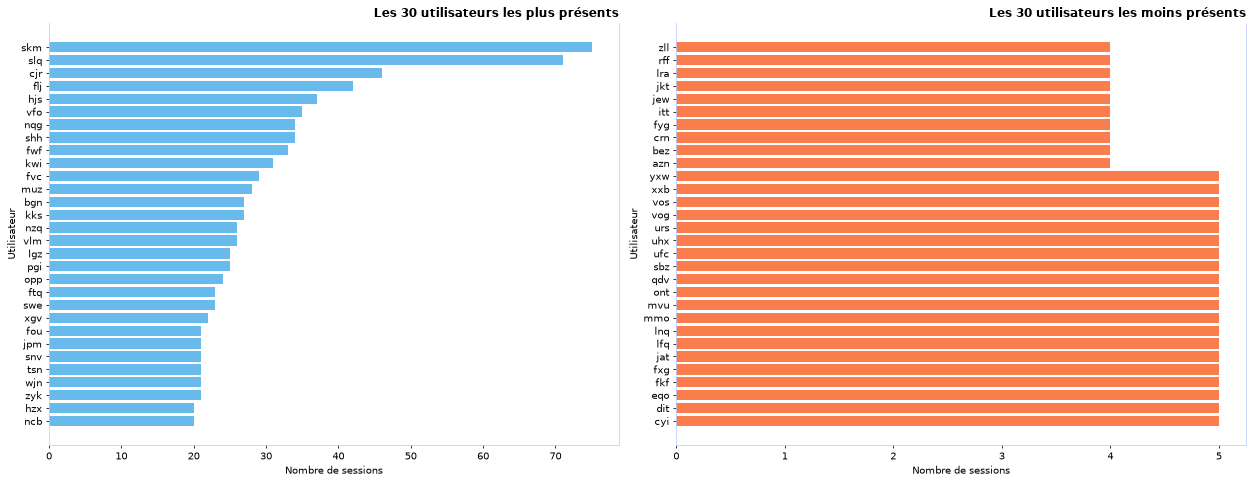

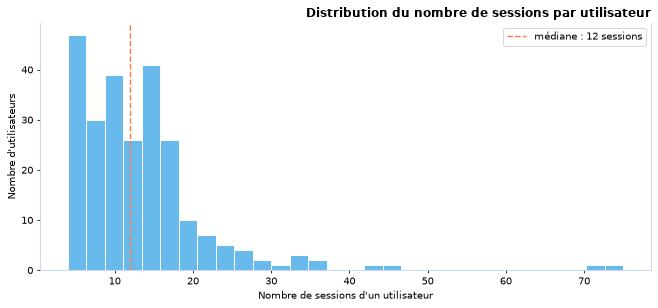

Un utilisateur a en médiane 12 sessions ; l'utilisateur le plus présent en a 75.


In [3]:
effectifs = features_train["util"].value_counts()
top30 = effectifs.head(30)
bas30 = effectifs.tail(30)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# --- Premier graphique : Les 30 utilisateurs les plus présents ---
axes[0].barh(top30.index[::-1], top30.values[::-1], color=BLEU)
axes[0].set_title("Les 30 utilisateurs les plus présents")
axes[0].set_xlabel("Nombre de sessions")
axes[0].set_ylabel("Utilisateur")

# --- Second graphique : Les 30 utilisateurs les moins présents ---
axes[1].barh(bas30.index, bas30.values, color=ORANGE)
axes[1].set_title("Les 30 utilisateurs les moins présents")
axes[1].set_xlabel("Nombre de sessions")
axes[1].set_ylabel("Utilisateur")

plt.tight_layout()
plt.show()

AN.plot_distribution(effectifs, 
    title = "Distribution du nombre de sessions par utilisateur",
    xlabel = "Nombre de sessions d'un utilisateur",
    ylabel = "Nombre d'utilisateurs"
)
print(f"Un utilisateur a en médiane {effectifs.median():.0f} sessions ; l'utilisateur le plus présent en a {effectifs.max()}.")


Chaque barre donne le nombre de sessions d'un utilisateur. Les utilisateurs les plus présents fournissent beaucoup d'exemples au modèle : ce sont les plus faciles à apprendre.
À l'opposé, ces utilisateurs n'ont que quelques sessions. Le modèle aura peu d'exemples pour apprendre leur façon de travailler : c'est sur eux que l'on attend le plus d'erreurs.

### Navigateurs utilisés
Est-ce que les utilisateurs sont fidèles à leurs navigateurs ? Quel navigateur est le plus utilisé?

In [4]:
# Nouvelle Dataframe
updated_df = pd.DataFrame({'util':features_train["util"].unique()})
updated_df["util"] = pd.Categorical(updated_df["util"])

Nombre maximum de navigateurs utilisés par un utilisateur: 1


,sessions,part (%),utilisateurs l'ayant utilisé
navigateur,,,
Firefox,1466,44.71,114
Google Chrome,1339,40.84,93
Microsoft Edge,451,13.75,39
Opera,23,0.70,1


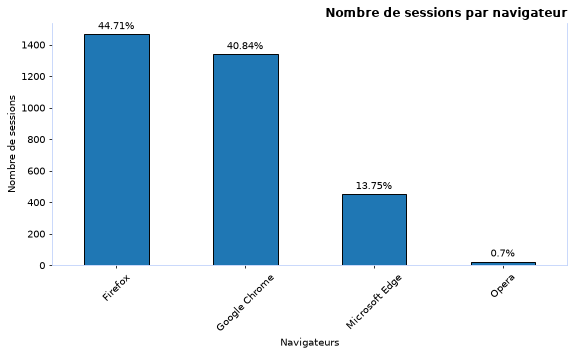

In [8]:
AN.browsers_analysis(features_train)

# Création d'une nouvelle df qui sera utilisée pour la classification
updated_df = features_train[["util","navigateur"]].groupby("util")["navigateur"].first().reset_index()
updated_df = AN.to_categories(updated_df,"navigateur")

Un utilisateur utilise toujours le même navigateur. Un seul d'entre eux utilise Opéra et sera donc facilement identifiable.

## 1.3 Analyse des actions
### Tableau des types d'action
Le type d'une action est son nom, sans l'écran ni la configuration (par exemple « Exécution d'un bouton »).

### Types d'action les plus liés aux utilisateurs : test du χ²

- Pour chaque type d'action, le test du χ² compare les fréquences d'utilisation de cette action des différents utilisateurs avec ce que l'on observerait si tous les utilisateurs l'employaient dans les mêmes proportions.

- Plus le score est élevé, plus l'usage de ce type d'action dépend de l'utilisateur et donc plus ce type d'action sera utile pour reconnaître quelqu'un.

On décide de garder tous les types d'actions ayant un score de chi2 supérieur à 0.25*max(scores_chi2).
On calcule la matrice de corrélation pour les grandeurs restantes. On remarque que l'action "Sélection d'un élément" est très fortement corréler à l'action "Désélection d'un élément", donc on ne garde qu'une des deux. D'après le tableau ci-dessus, 226 utilisateurs sur 247 utilise l'action "Sélection d'un élément" (cette action appraraît également dans beaucoup de sessions) donc on va plutôt garder "Désélection d'un élément" qui est moins répandue (12 utilisateurs seulement).

On procède de la même manière pour les fiches, écrans et configurations pour ne garder que ceux très dépendant de l'utilisateur.

2270247


Type d'action,Occurrences,Part des actions,Sessions où il apparaît,Utilisateurs qui l'emploient
Retour sur un écran,16,0.000705,15,14
Création d'un écran,230,0.010131,55,8
Affichage d'une dialogue,298,0.013126,36,12
Exécution d'un bouton,307,0.013523,185,86
Ouverture d'un panel,682,0.030041,486,127
Raccourci dans l'édition de table,1710,0.075322,97,37
Filtrage / Tri,1925,0.084793,1812,241
Désélection d'un élément,2913,0.128312,637,175
Sélection d'un élément,3800,0.167383,580,157
Dissimulation d'une arborescence,5704,0.251250,661,163


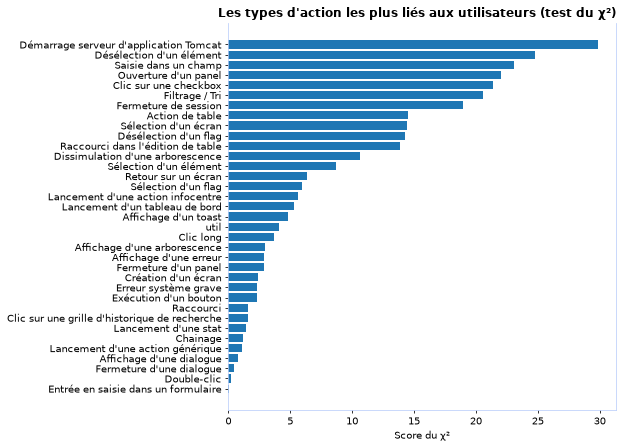

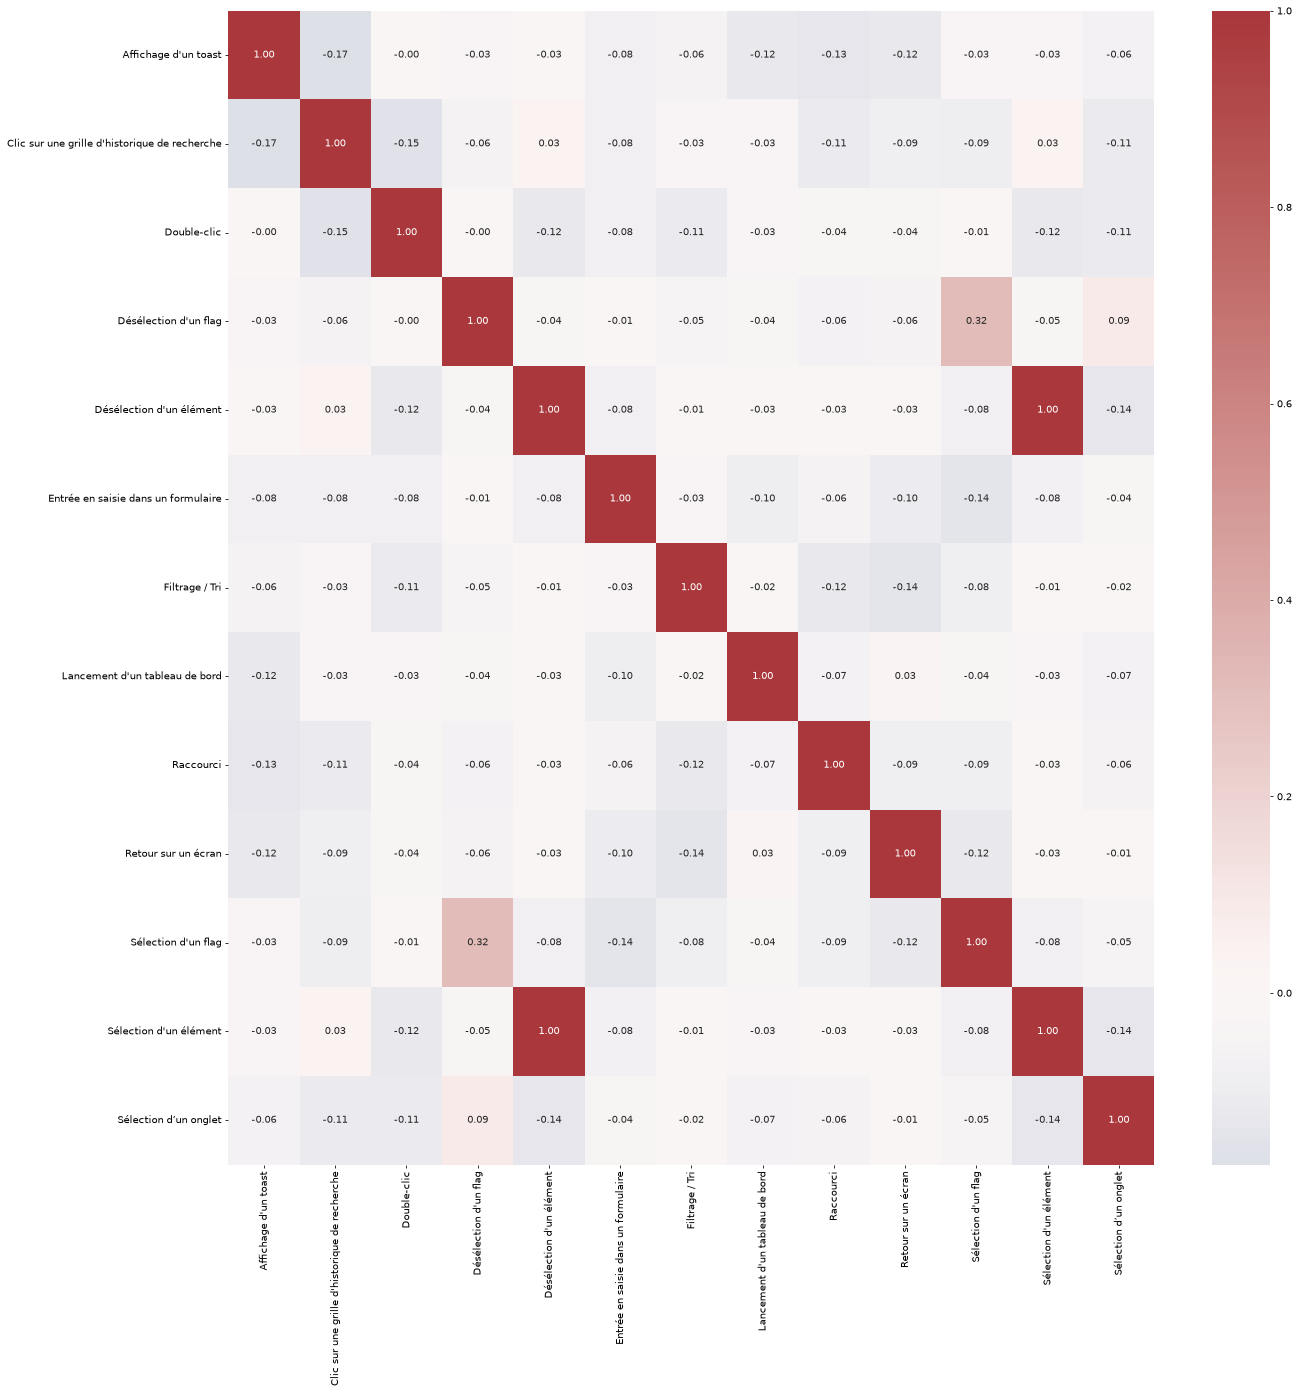

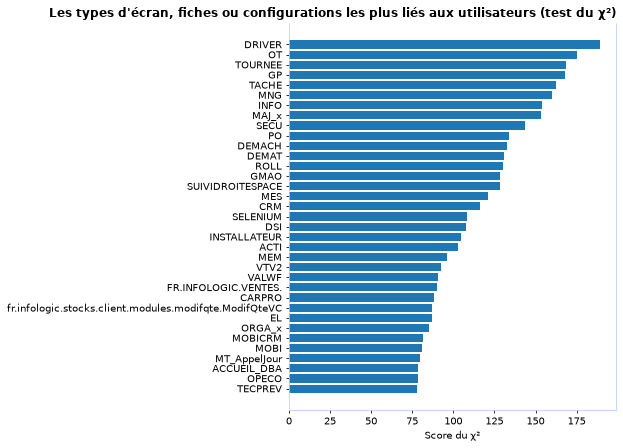

['ACTI', 'ALCOOL', 'DB', 'DEMAT', 'DEVOPS', 'DSI', 'EDI', 'EL', 'ETAT', 'GESCO_x', 'GP', 'IADEV', 'INFO', 'JCP', 'MEM', 'MES', 'MNG', 'MOBI', 'MOBICRM', 'MOBITOUR', 'ORGA_x', 'OT', 'PDP', 'PO', 'POORGA', 'SECU', 'SELENIUM', 'ST', 'SV', 'TEC', 'TLP', 'TRACE', 'VT', 'VTPREV', 'WEB', 'CVRH', 'fr.infologic.superviseur.client.modules.postpreparation.PostPreparationVC', 'infologic.crm.modules.CRM_COMPTE.CompteForm', 'infologic.global.modules.GL_QUESTIONNAIRE.campagne.AdminReponseQuestionnaireForm', 'infologic.infoc.tableaubord.TableauBordController', 'infologic.ventes.modules.VT_CONTRATMAINT.contratsmaint.ContratMaintForm', '002', 'ACCUEIL_DBA', 'ACCUEIL_DSI', 'ACCUEIL_MAJ', 'ACCUEIL_TECH', 'ACCUEIL_TEST', 'CCR', 'CONFWHE', 'CONF_CONTACTSPR', 'ChantierInstallation', 'DEFbti', 'FICHEACT_OP', 'INSTALLATION', 'KanbanProjet', 'MSE', 'MT_AppelN1', 'PROC - Défaut', 'dispatch']
59


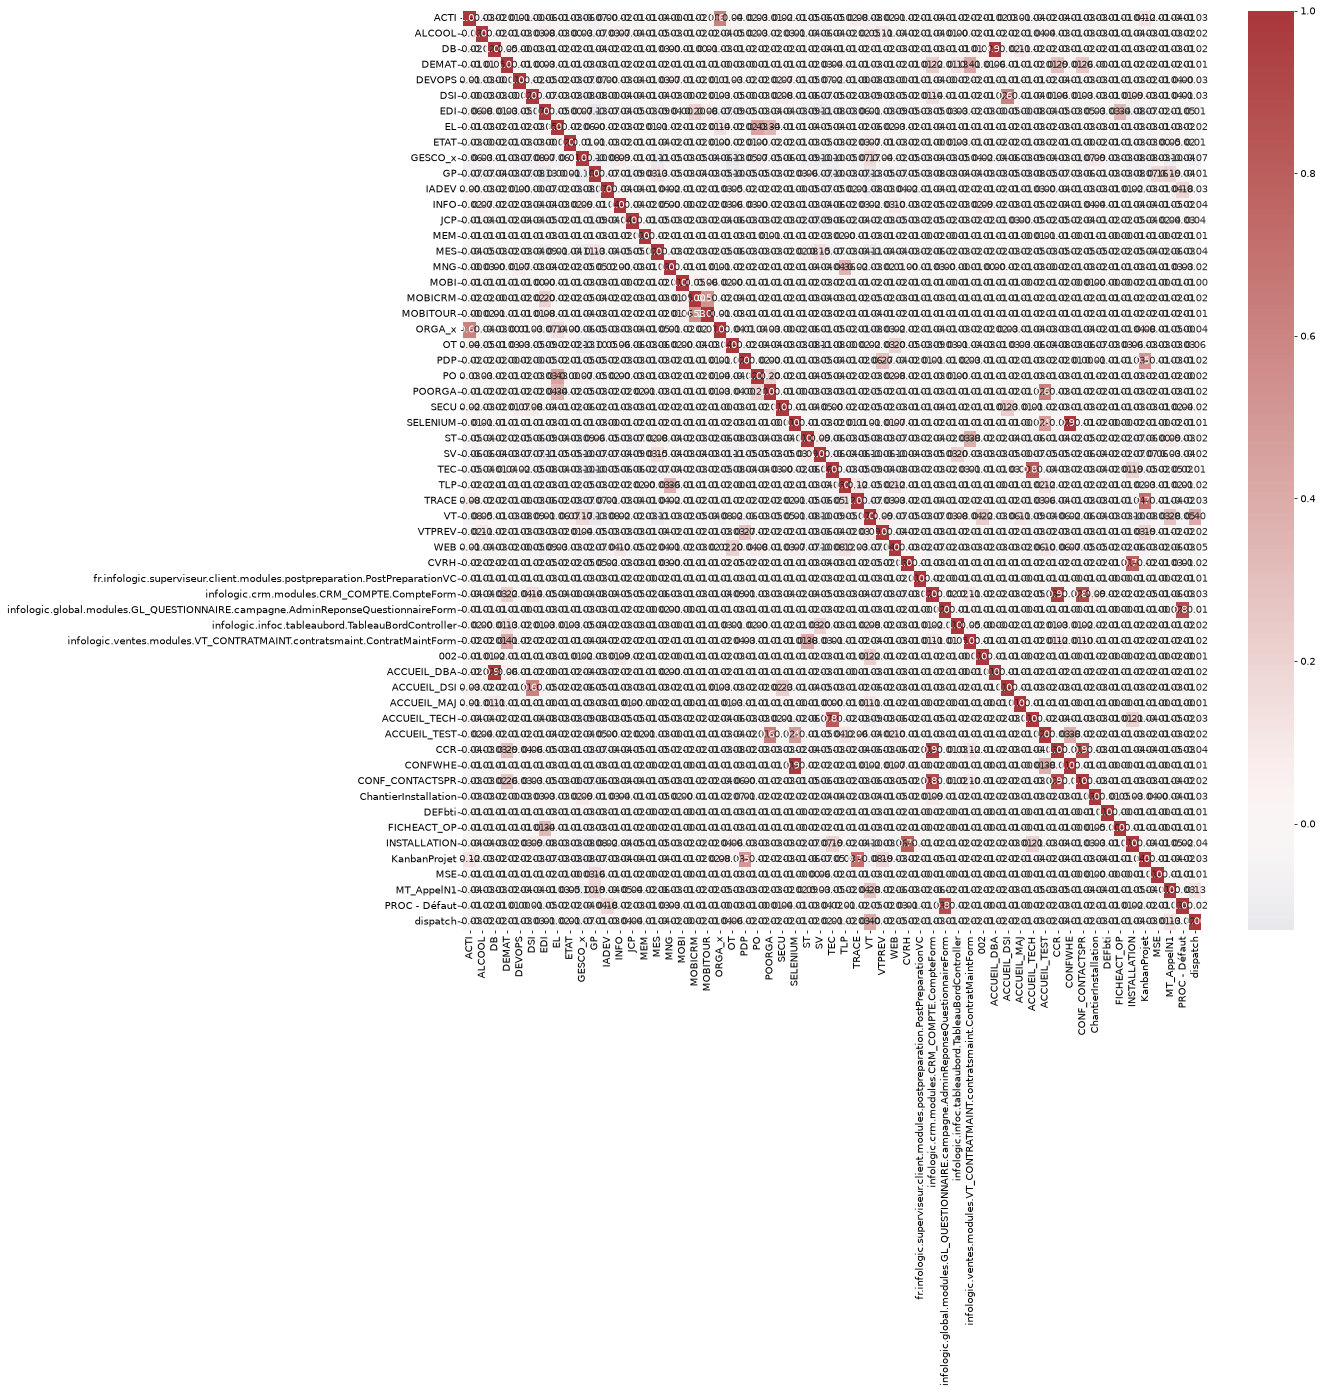

In [9]:
# Récuperer la liste des actions différentes 
uniques = features_train.iloc[:,2:].stack().unique()
filtered_uniques = list(set([AN.filter_action(un) for un in uniques if isinstance(un, str) and not un.startswith("t")]))
len(filtered_uniques)

updated_df = AN.actions_analysis(features_train,filtered_uniques)

fiches = AN.fun(features_train,[r'\$(.*?)\$',r'\((.*?)\)',r'\<(.*?)\>'])
print(fiches)
print(len(fiches))

### 1.5 Analyse temporelle

Plus longue session: 11790.0


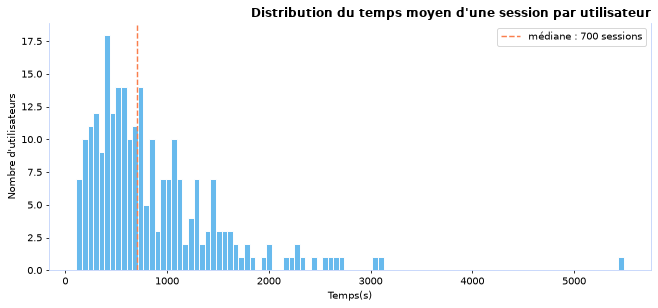

In [5]:
updated_df = AN.temps_par_session(features_train,updated_df)

max_val = updated_df["max_t"].max()
bin_width = 120 # 60: regroupe par minute, 300 regroupe par 5 min
print(f"Plus longue session: {max_val}")

AN.plot_distribution(
    effectifs = updated_df["moyenne_t"], 
    title = "Distribution du temps moyen d'une session par utilisateur",
    xlabel = "Temps(s)",
    ylabel = "Nombre d'utilisateurs", 
    bins = int(max_val/bin_width)
)

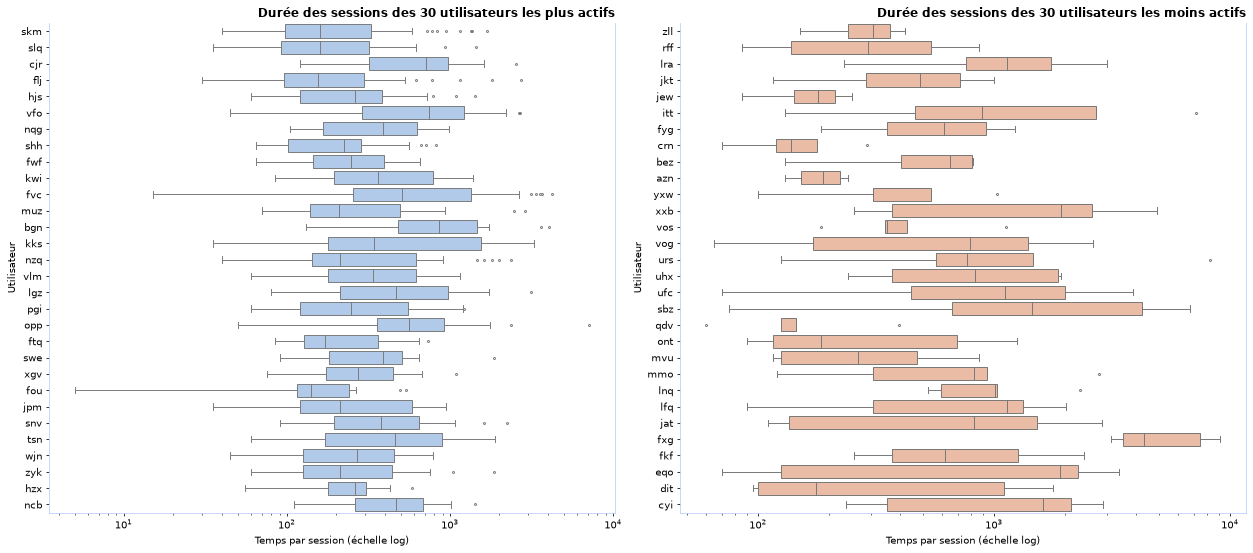

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

# --- Premier graphique (sur le premier axe: axes[0]) ---
sns.boxplot(
    data=features_train[features_train["util"].isin(top30.index)], 
    y="util", x="max_t", order=top30.index,
    color="#a9c9f2", fliersize=2, linewidth=1, 
    ax=axes[0]
)

axes[0].set_xscale("log")
axes[0].set_title("Durée des sessions des 30 utilisateurs les plus actifs")
axes[0].set_xlabel("Temps par session (échelle log)")
axes[0].set_ylabel("Utilisateur")

sns.boxplot(
    data=features_train[features_train["util"].isin(bas30.index)], 
    y="util", x="max_t", order=bas30.index[::-1],
    color="#f5b899", fliersize=2, linewidth=1,
    ax=axes[1]
)

axes[1].set_xscale("log")
axes[1].set_title("Durée des sessions des 30 utilisateurs les moins actifs")
axes[1].set_xlabel("Temps par session (échelle log)")
axes[1].set_ylabel("Utilisateur")

plt.tight_layout()
plt.show()

In [6]:
# Retire les outliers
features_clean = features_train.groupby("util", group_keys=True).apply(AN.remove_outliers_per_user)
features_clean = features_clean.reset_index(level='util', drop=False)

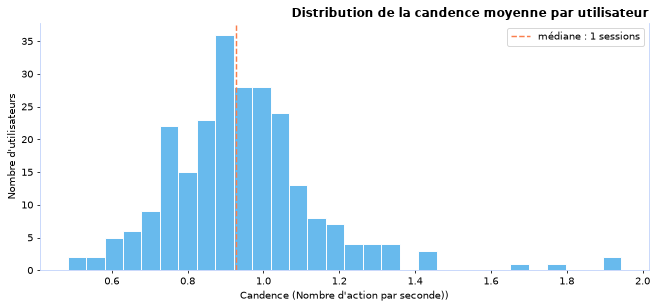

In [7]:
df = AN.rapidite_util(features_clean,updated_df)

AN.plot_distribution(
    effectifs = df["rapidite"], 
    title = "Distribution de la candence moyenne par utilisateur",
    xlabel = "Candence (Nombre d'action par seconde))",
    ylabel = "Nombre d'utilisateurs", 
)
# regarder + précisement 30 premières secondes

In [ ]:
# A voir si on garde
AN.stat_actions(features_train,updated_df)

updated_df[["mean_changement_ecran","mean_ecran","mean_fiche","mean_modif"]].hist(bins=30, edgecolor="black")
#updated_df.head()

# Partie reprise tel quel du code de hajar
On ne lit pas les données initiales de la même manière. Il reste à aligner ce code sur la manière de lire donnée par le prof (ou alors adapter la première partie à cette manière de lire)

In [ ]:
import analyse_donnees as AN2
import numpy as np

fichier_train = AN2.trouver("train.csv")
train_brut, train_lignes_vides = AN2.lire_sessions(fichier_train, avec_utilisateur=True)
train = pd.DataFrame([{"util": s["util"], "navigateur": s["navigateur"], "empreinte": hash(tuple(s["jetons"])),
                       **AN2.decrire_session(s["jetons"])} for s in train_brut])
train["log_actions"] = np.log1p(train["n_actions"])
train["log_duree"] = np.log1p(train["duree_s"])


### Types d'action sur- et sous-représentés selon les utilisateurs

our chacun des 30 utilisateurs les plus actifs et chacun de ces 20 types d'action, on compare la part de ce type dans ses actions à la part moyenne sur tous les utilisateurs, en log base 2 :

**+1** = deux fois plus que la moyenne (orange), 

**−1** = deux fois moins (bleu), **0** = comme tout le monde (blanc).

 Chaque ligne est une sorte d'« empreinte » : deux utilisateurs dont les lignes diffèrent beaucoup seront
faciles à distinguer.

In [ ]:
compteur_types = CountVectorizer(token_pattern=r"\S+", lowercase=False)
X_types = compteur_types.fit_transform(train["doc_types"])
noms_types = compteur_types.get_feature_names_out()

parts = pd.DataFrame(X_types.toarray(), columns=[value.replace("_", " ") for value in noms_types])
parts["util"] = train["util"].to_numpy()
comptes_u = parts.groupby("util").sum()
part_u = comptes_u.div(train.groupby("util")["n_actions"].sum(), axis=0)
part_moyenne = comptes_u.sum() / train["n_actions"].sum()
ecart = np.log2((part_u + 1e-4) / (part_moyenne + 1e-4)).loc[top30.index]

plt.figure(figsize=(11, 8))
sns.heatmap(ecart, cmap=sns.diverging_palette(250, 25, as_cmap=True), center=0, vmin=-3, vmax=3,
            linewidths=0.4, linecolor="white", cbar_kws={"label": "log2(part chez l'utilisateur / part moyenne)"})
plt.title("Types d'action sur- et sous-représentés (30 utilisateurs les plus actifs)")
plt.xlabel("")
plt.ylabel("Utilisateur")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Enchaînement des actions
 On compte les paires d'actions consécutives (« bigrammes ») : par exemple « Saisie dans un
champ → Exécution d'un bouton ».

Deux personnes peuvent faire les mêmes actions dans un ordre différent :
l'ordre est une information supplémentaire pour les reconnaître.

In [ ]:
paires = Counter()
for doc in train["doc_types"]:
    ty = doc.split()
    paires.update(zip(ty, ty[1:]))

top_paires = paires.most_common(15)[::-1]
plt.figure(figsize=(9, 6))
plt.barh([f"{a.replace('_', ' ')} → {b.replace('_', ' ')}" for (a, b), _ in top_paires], [c for _, c in top_paires], color=BLEU)
plt.title("Les 15 enchaînements d'actions les plus fréquents")
plt.xlabel("Nombre d'occurrences")
plt.tight_layout()
plt.show()

Les enchaînements les plus fréquents sont souvent des répétitions (une saisie suivie d'une autre saisie) ou des
séquences logiques du logiciel (ouvrir une dialogue puis la fermer).

### Matrice de transition entre les 15 types d'action les plus fréquents
**Ce qui est calculé.** Chaque case donne la probabilité que l'action de la colonne suive l'action de la ligne :
on divise le nombre de transitions « ligne → colonne » par le nombre total de transitions qui partent de la ligne.
Chaque ligne fait donc 100 %. **Intérêt.** Si les utilisateurs ont des habitudes d'enchaînement différentes, les
paires d'actions consécutives aideront le modèle (on les utilisera comme variables en Section 2).

In [ ]:
tous_types = Counter(a for doc in train["doc_types"] for a in doc.split()) 
frequents = [ty for ty, _ in tous_types.most_common(15)]
transitions = pd.DataFrame(0.0, index=frequents, columns=frequents)
for (a, b), c in paires.items():
    if a in transitions.index and b in transitions.columns:
        transitions.loc[a, b] = c
transitions = transitions.div(transitions.sum(axis=1), axis=0)
etiquettes = [ty.replace("_", " ") for ty in frequents]

plt.figure(figsize=(11, 8.5))
sns.heatmap(transitions.set_axis(etiquettes).set_axis(etiquettes, axis=1), cmap="Blues", annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", cbar_kws={"label": "Probabilité de transition"})
plt.title("Matrice de transition entre les 15 types d'action les plus fréquents")
plt.xlabel("Action suivante")
plt.ylabel("Action courante")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Une case foncée signale un enchaînement très probable. La diagonale correspond aux répétitions d'une même action.

## 1.4 Comparaison des utilisateurs entre eux

**Sur quels critères ?** On compare les utilisateurs sur **les actions qu'ils utilisent et leur fréquence**, en
prenant le jeton d'action complet (type + écran + configuration + chaîne), qui est la description la plus précise.

**Comment est-ce calculé ?**
1. Chaque session est transformée en vecteur **TF-IDF** : une case par jeton d'action. La valeur augmente quand le
   jeton est fréquent dans la session (TF) et diminue quand il est présent dans presque toutes les sessions (IDF), car
   un jeton que tout le monde utilise n'aide pas à distinguer les personnes.
2. Le **profil** d'un utilisateur est la moyenne des vecteurs de ses sessions.
3. On compare deux profils avec la **similarité cosinus** : 1 si les deux utilisateurs utilisent les mêmes actions
   dans les mêmes proportions, 0 s'ils n'ont aucune action en commun.

**Comment interpréter ?** Une similarité faible entre deux utilisateurs signifie qu'ils travaillent différemment
(autres écrans, autres modules) : le modèle les séparera facilement. Une similarité forte signale deux personnes au
comportement proche (même poste, mêmes tâches) : ce sont elles que le modèle risque de confondre.

**Intérêt pour la modélisation.** Si la plupart des paires sont peu similaires, une représentation TF-IDF des actions
est un bon point de départ pour le modèle d'identification.

In [ ]:
tfidf_eda = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True, min_df=2)
X_eda = tfidf_eda.fit_transform(train["doc_actions"])

utilisateurs = effectifs.index
profils = np.vstack([np.asarray(X_eda[(train["util"] == u).to_numpy()].mean(axis=0)) for u in utilisateurs])
profils = normalize(profils)
similarites = pd.DataFrame(profils @ profils.T, index=utilisateurs, columns=utilisateurs)

plt.figure(figsize=(10, 8.5))
sns.heatmap(similarites.loc[top30.index, top30.index], cmap="Blues", vmin=0, vmax=1, square=True,
            cbar_kws={"label": "Similarité cosinus", "shrink": 0.8})
plt.title("Similarité entre les profils des 30 utilisateurs les plus actifs")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

La diagonale vaut 1 (chaque utilisateur est identique à lui-même). Hors de la diagonale, une case claire indique deux
utilisateurs très différents, une case foncée deux utilisateurs proches.

In [ ]:
haut = np.triu_indices(len(utilisateurs), k=1)
valeurs = similarites.to_numpy()[haut]

plt.figure()
plt.hist(valeurs, bins=40, color=BLEU, edgecolor="white")
plt.axvline(np.median(valeurs), color=ORANGE, linestyle="--", label=f"médiane : {np.median(valeurs):.2f}")
plt.title("Similarité entre toutes les paires d'utilisateurs")
plt.xlabel("Similarité cosinus")
plt.ylabel("Nombre de paires d'utilisateurs")
plt.legend()
plt.tight_layout()
plt.show()

plus_proches = np.argsort(-valeurs)[:5]
print("Paires d'utilisateurs les plus proches (risque de confusion) :")
for i in plus_proches:
    print(f"  {utilisateurs[haut[0][i]]} et {utilisateurs[haut[1][i]]} : similarité {valeurs[i]:.2f}")

Si l'essentiel des paires se trouve à gauche (similarité faible), les utilisateurs ont des façons de travailler bien
distinctes. Les quelques paires très proches listées ci-dessus sont à surveiller lors de l'évaluation du modèle.

## 1.6 Composants logiciels
Les parties entre parenthèses, chevrons et dollars indiquent **où** l'utilisateur travaille dans le logiciel.
Chaque personne n'utilise qu'une partie du logiciel, selon son métier : ces composants sont donc de bons indices
d'identité.

In [ ]:
chaines = Counter(c for liste in train["chaines"] for c in liste)
AN.barres_top(chaines, f"Chaînes de fiches les plus utilisées ({len(chaines)} distinctes)", "Nombre d'actions")

configs = Counter(c for liste in train["configs"] for c in liste)
AN.barres_top(configs, f"Configurations d'écran les plus utilisées ({len(configs)} distinctes)", "Nombre d'actions")

ecrans = Counter(e for liste in train["ecrans"] for e in liste)
AN.barres_top(ecrans, f"Écrans et contrôleurs les plus utilisés ({len(ecrans)} distincts)", "Nombre d'actions")

modules = Counter()
for e, c in ecrans.items():
    modules[AN.module(e)] += c
AN.barres_top(modules, "Modules du logiciel les plus sollicités", "Nombre d'actions", n=12)

Les **chaînes de fiches** (entre dollars, par exemple `$EDI$`) indiquent le circuit de documents sur lequel
l'utilisateur travaille. Une chaîne propre à un service est un indice fort sur le métier, donc sur la personne.
Les **configurations d'écran** (entre chevrons) sont des réglages d'affichage. Certaines semblent personnelles ou
propres à une équipe : un utilisateur qui utilise toujours la même configuration se trahit par ce simple détail.
Les **écrans et contrôleurs** (entre parenthèses) sont les pages du logiciel ouvertes par l'utilisateur. Leur nom
complet est long : on n'affiche que la fin, la plus parlante.
Le **module** est déduit du nom de l'écran (le mot qui suit `infologic`, par exemple `crm` ou `compta`) ; les écrans
sans nom complet sont regroupés sous « code court ». Ce regroupement donne une vue d'ensemble des grandes fonctions
du logiciel : un utilisateur de la comptabilité et un utilisateur du CRM n'ouvriront pas les mêmes modules.